In [1]:
import numpy as np
import astropy
from astropy import units as u
from astropy.constants import m_e
import matplotlib.pyplot as plt
from scipy.special import kv

from agnpy.emission_regions import Blob
from agnpy.spectra import PowerLaw, BrokenPowerLaw, LogParabola, ExpCutoffPowerLaw
from agnpy.synchrotron import Synchrotron
from agnpy.synchrotron import R, G
from scipy.integrate import simpson

def pol_degree_power_law (p):
    return (p + 1) / (p + 7/3)

def check_args (y, x):
    if isinstance(x, astropy.units.Quantity):
        x_unit = x.unit
        x = x.to_value(x_unit)
    else:
        x_unit = u.dimensionless_unscaled
    if isinstance(y, astropy.units.Quantity):
        y_unit = y.unit
        y = y.to_value(y_unit)
    else:
        y_unit = u.dimensionless_unscaled
    return y, x, y_unit, x_unit

def linear_simpson (y, x, **kwargs):
    y, x, y_unit, x_unit = check_args(y, x)
    integral = simpson(y, x=x, **kwargs)
    return integral * y_unit * x_unit

def log_simpson (y, x, **kwargs):
    y, x, y_unit, x_unit = check_args(y, x)
    integral = simpson(y * x, x=np.log(x), **kwargs)
    return integral * y_unit * x_unit

/home/cerasole/miniforge3/envs/agnpy/lib/python3.11/site-packages/astropy/units/quantity.py:676: RuntimeWarning: invalid value encountered in divide
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)
/home/cerasole/miniforge3/envs/agnpy/lib/python3.11/site-packages/astropy/units/quantity.py:676: RuntimeWarning: invalid value encountered in divide
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)
/home/cerasole/miniforge3/envs/agnpy/lib/python3.11/site-packages/astropy/units/quantity.py:676: RuntimeWarning: invalid value encountered in divide
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


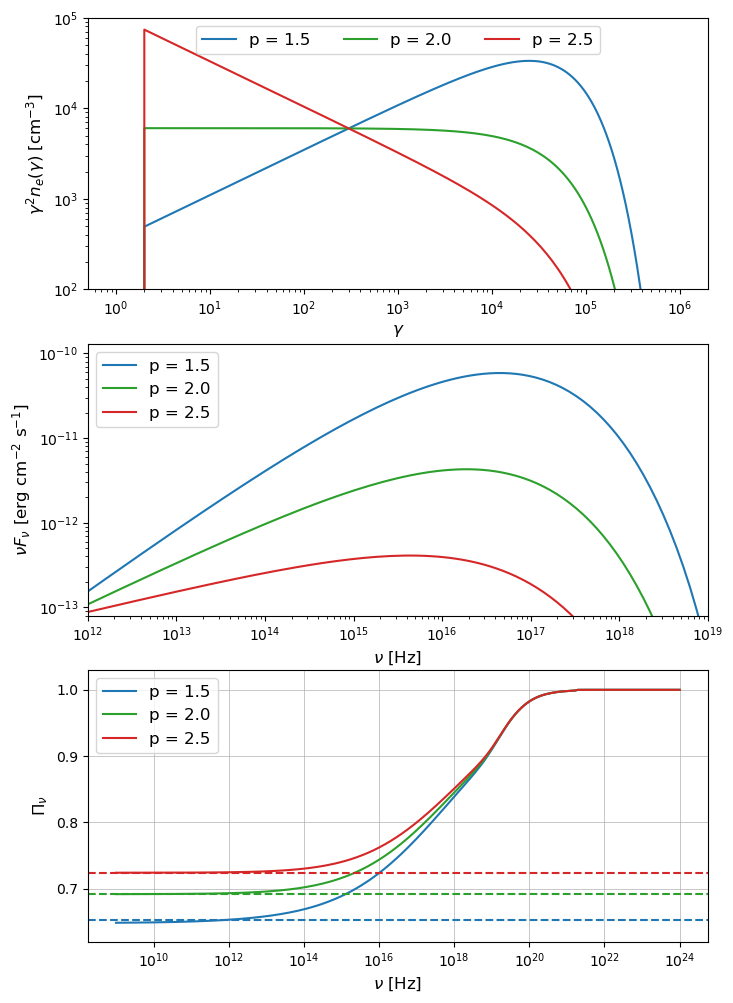

In [2]:
nu = np.logspace(9, 24, 200) * u.Hz
gamma = np.logspace(0, 6, 200)

gcut = 5e4
spectral_indices = [1.50, 2.00, 2.50]
colors = ["tab:blue", "tab:green", "tab:red"]

fig, axs = plt.subplots(3, 1, figsize=(8, 12))

gamma_ref = 3e2
dnde_ref = 6e3 * u.Unit('cm-3')
k0 = 1 * u.Unit('cm-3')
R_b = 1e16 * u.cm

for i, p in enumerate(spectral_indices):    
    n_e = ExpCutoffPowerLaw(
        k0,
        p = p, 
        gamma_c = gcut, gamma_min = 20, gamma_max = 5e5, 
        mass = m_e
    )
    k = k0 * dnde_ref / n_e(gamma_ref) / gamma_ref**2
    n_e = ExpCutoffPowerLaw(
        k,
        p = p, 
        gamma_c = gcut, gamma_min = 2, gamma_max = 5e5, 
        mass = m_e
    )

    blob = Blob(n_e = n_e, R_b = R_b, z = 0.05, B = 0.7 * u.G, delta_D=4,)
    synch = Synchrotron(blob, ssa = False)
    synch_sed = synch.sed_flux(nu)
    pol_degree = synch.polarization_degree(nu)

    axs[0].loglog(gamma, (n_e(gamma)*gamma**2).to("cm-3"), label='p = {}'.format(p), color = colors[i])
    axs[1].loglog(nu, synch_sed, label='p = {}'.format(p), color = colors[i])
    axs[2].plot(nu, pol_degree, label='p = {}'.format(p), color = colors[i])
    axs[2].axhline(pol_degree_power_law(p), linestyle='--', color = colors[i])

ax = axs[0]
ax.set_ylim(1e2, 1e5)
ax.set_xlabel(r'$\gamma$', fontsize=12)
ax.set_ylabel(r'$\gamma^2 n_e(\gamma)$ [cm$^{-3}$]', fontsize=12)
ax.legend(loc='upper center', fontsize=12, ncol = 3);

ax = axs[1]
ax.set_ylim(0.8e-13, 1.3e-10)
ax.set_xlim(1e12, 1e19)
ax.set_xlabel(r'$\nu$ [Hz]', fontsize=12)
ax.set_ylabel(r'$\nu F_\nu$ [erg cm$^{-2}$ s$^{-1}$]', fontsize=12)
ax.legend(loc='upper left', fontsize=12);

ax = axs[2]
ax.set_xscale('log')
ax.grid(lw = 0.5)
ax.set_ylim(0.62, 1.03)
#ax.set_xlim(1e12, 1e24)
ax.set_xlabel(r'$\nu$ [Hz]', fontsize=12)
ax.set_ylabel(r'$\Pi_{\nu}$', fontsize=12)
ax.set_yticks([0.7, 0.8, 0.9, 1.0])
ax.legend(loc='upper left', fontsize=12);

/home/cerasole/miniforge3/envs/agnpy/lib/python3.11/site-packages/astropy/units/quantity.py:676: RuntimeWarning: invalid value encountered in divide
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


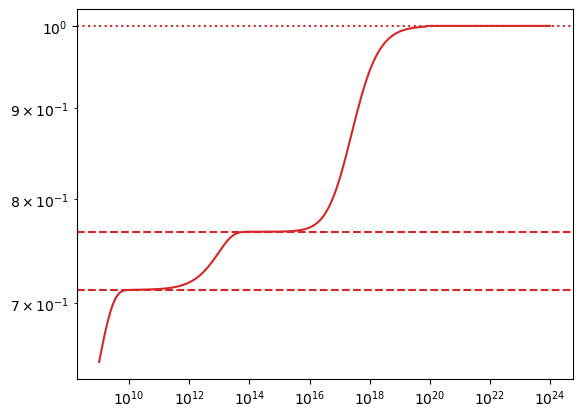

In [5]:
p1, p2 = 2.3, 3.4
blob = Blob(n_e = BrokenPowerLaw(p1 = p1, p2 = p2, gamma_b = 1000, gamma_min = 10, gamma_max = 1e5), R_b = R_b, z = 0.05, B = 0.7 * u.G, delta_D=4,)
synch = Synchrotron(blob, ssa = False)
pol_degree = synch.polarization_degree(nu)

plt.loglog(nu, pol_degree, color = colors[i])
plt.axhline(pol_degree_power_law(p1), linestyle='--', color = colors[i])
plt.axhline(pol_degree_power_law(p2), linestyle='--', color = colors[i])
plt.axhline(1, ls='dotted', color = colors[i])

/home/cerasole/miniforge3/envs/agnpy/lib/python3.11/site-packages/astropy/units/quantity.py:676: RuntimeWarning: invalid value encountered in divide
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


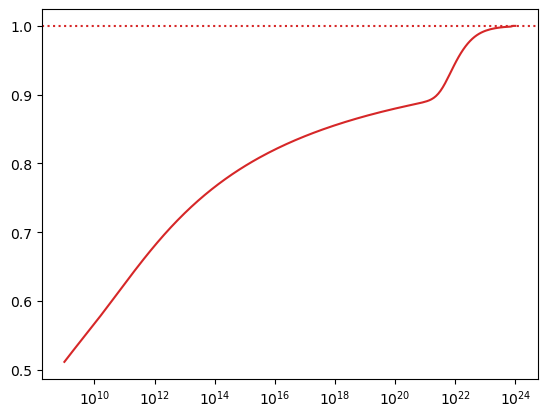

In [6]:
p1, p2 = 2.3, 3.4
blob = Blob(n_e = LogParabola(p=2.3, q=1), R_b = R_b, z = 0.05, B = 0.7 * u.G, delta_D=4,)
synch = Synchrotron(blob, ssa = False)
pol_degree = synch.polarization_degree(nu)

plt.plot(nu, pol_degree, color = colors[i])
plt.xscale('log')
plt.axhline(1, ls='dotted', color = colors[i])